# Hybrid diffractive lenses: kinoform achromats, apochromats and a thermal singlet

A **diffractive surface** carries a kinoform, a relief of zones whose
phase steps are one wave deep, on a lens surface. It bends light by the
local grating equation, not by Snell's law, and its power grows in
proportion to the wavelength: red is bent more than blue, the opposite
of glass, and about twenty times as strongly. A weak kinoform on one
face of a lens therefore corrects the colour of the lens, a *hybrid*
refractive-diffractive lens. This is how many infrared lenses, phone
camera modules and VR eyepieces save an element.

`raytrace.DiffractiveSurface` adds such a surface to the sequential ray
tracer: a rotationally symmetric phase polynomial on any base surface,
traced with the local grating equation, with its paraxial power, its
Seidel sums and primary colour (from the Sweatt model) and the
diffraction efficiency of the kinoform. `lens_optimization.diffractive()`
makes its phase coefficients variables of the damped least squares
optimizer.

1. The diffractive surface: phase, zones and the local grating equation
2. The Sweatt model: a lens of huge index as a check of the Seidel sums
3. Dispersion: Abbe number −3.45 and a partial dispersion far below the glasses
4. A hybrid achromat against the glass doublet of notebook [61 (glass catalogues)](61_glass_catalogues.ipynb)
5. A hybrid apochromat from two ordinary glasses
6. Efficiency: where the light of the other orders goes
7. A hybrid singlet for thermal imaging (8 to 12 µm)

**Why it matters.** Colour correction normally needs two glasses of
different dispersion, and an apochromat needs anomalous, expensive
glasses or three elements. A kinoform adds a "material" with an
extreme negative Abbe number at almost no weight or cost, at the price of
light in unwanted diffraction orders.

**Before this notebook:** notebooks [58 (lens optimization)](58_lens_optimization.ipynb)
(damped least squares) and [61 (glass catalogues)](61_glass_catalogues.ipynb)
(secondary spectrum and partial dispersion); the kinoform itself, as
the limit of a Fresnel lens, appears in notebook
[51 (Fresnel lenses)](51_fresnel_lenses.ipynb). Related: the diffractive
spot splitter of notebook [48 (laser head DOE)](48_laser_head_doe.ipynb),
gratings traced as surfaces in notebook
[110 (grating and prism spectrometers)](110_grating_prism_spectrometers.ipynb) and the
in- and out-couplers of notebook [123 (AR waveguide combiners)](123_ar_waveguide_combiners.ipynb).

Tools: `raytrace.DiffractiveSurface`, `System.sweatt_model()`,
`System.diffraction_efficiency()`, `System.kinoform_depth()`,
`lens_optimization.DiffractivePhase`/`diffractive()`, `glasses`,
`materials.zinc_selenide_index()`, `materials.germanium_index()`,
`sketch.hybrid_lens_layout()`

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import fresnel
from pyoptics import glasses as gl
from pyoptics import lens_optimization as lo
from pyoptics import raytrace as rt
from pyoptics import sketch
from pyoptics.materials import germanium_index, zinc_selenide_index

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.grid": True, "grid.color": "0.88", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
t_start = time.time()

WL = {k: gl.LINES[k]*1e-6 for k in "gFdC"}   # mm
BLUE, ORANGE, GREEN, RED, PURPLE, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#d03b3b", "#7b5cc4", "#888888"
BK7, F2 = gl.get("N-BK7"), gl.get("N-F2")

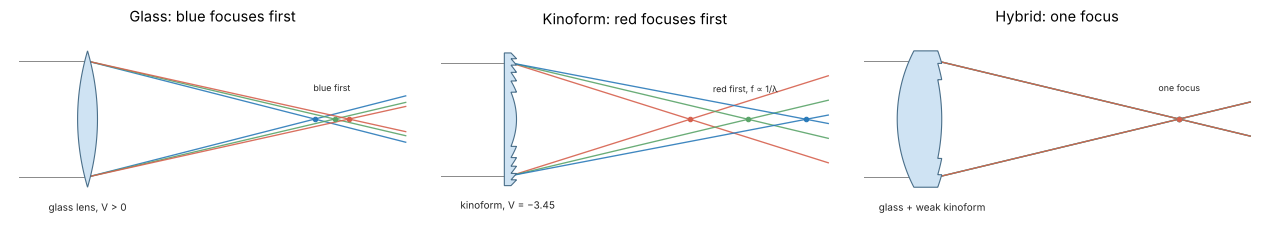

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, kind, title in zip(axes, ("refractive", "diffractive", "hybrid"),
                           ("Glass: blue focuses first", "Kinoform: red focuses first",
                            "Hybrid: one focus")):
    sketch.hybrid_lens_layout(ax, kind, title=title)
fig.tight_layout()

The idea in one picture. A glass lens bends blue more than red. A
kinoform bends red more than blue, and its focal length changes with the
wavelength twenty times faster than that of a crown glass lens. A
plano-convex lens that carries a kinoform of about 5 % of its power
brings blue and red to one focus.

## 1. The diffractive surface

The surface is described by a phase in radians,

$$
\phi(r) = \sum_k A_k \left(\frac{r}{r_n}\right)^{2k},
$$

the "Binary 2" surface of commercial codes. The phase describes the zone
structure: the kinoform is cut where $\phi$ passes multiples of $2\pi$,
and $\phi$ itself does not depend on the wavelength. A ray of wavelength
$\lambda$ in the diffraction order $m$ meets the surface where the zones
form a grating of the local period $\Lambda(r) = 2\pi/|\phi'(r)|$, and
leaves by the local grating equation on the tangent plane,

$$
n'\,\mathbf d'_t = n\,\mathbf d_t + \frac{m\lambda}{2\pi}\nabla_t\phi ,
$$

which is what `GratingSurface` does with a constant period. The optical
path gains $m\lambda\phi/2\pi$, so that the OPD behind the surface is the
phase of the diffracted wave. Paraxially the $r^2$ term is a thin lens of
power

$$
\varphi_D = -\frac{m\lambda A_1}{\pi r_n^2},
$$

proportional to $\lambda$. The zone radii of a lens of focal length $f$
are $r_j \approx \sqrt{2 j \lambda_0 f}$, the zones get narrower towards
the rim, and the relief is $\lambda_0/(n-1)$ deep, about 1.1 µm in N-BK7.

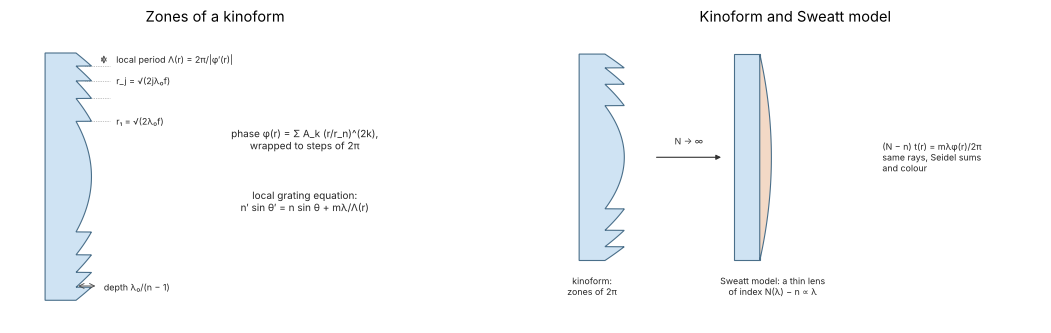

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
sketch.hybrid_lens_layout(axes[0], "kinoform", title="Zones of a kinoform")
sketch.hybrid_lens_layout(axes[1], "sweatt", title="Kinoform and Sweatt model")
fig.tight_layout()

A diffractive lens of f = 100 mm at the d line on a plane plate,
10 mm semi-diameter: its zones, the local period, and a check of one
ray against a `GratingSurface` with the local period at that height.

A_1 = -5346.8 rad, efl 100.000 mm
850 zones, first at r = 343 µm (sqrt(2 lambda f) = 343 µm), narrowest period 5.88 µm at the rim
direction behind the DOE     : [ 0.         -0.07        0.99754699]
direction behind the grating : [-0.         -0.07        0.99754699]


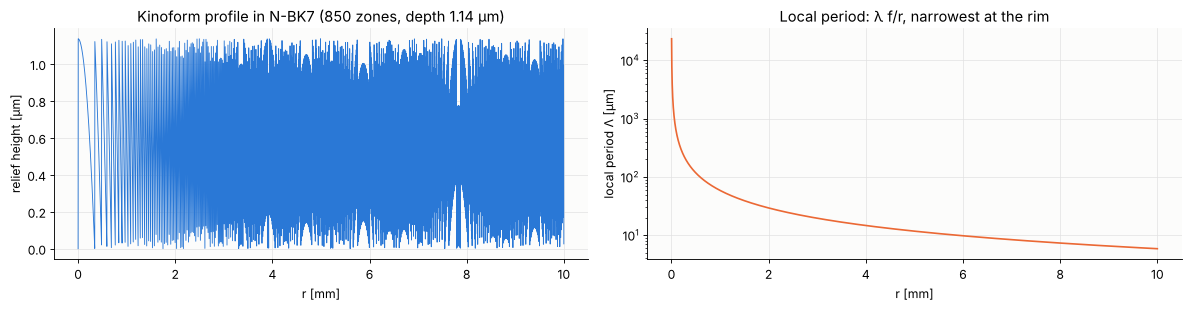

In [4]:
f, rn = 100.0, 10.0
doe = rt.DiffractiveSurface.from_power(1/f, WL["d"], thickness=f, norm_radius=rn, semi_diameter=rn)
lens = rt.System([doe], 0, WL["d"])
print(f"A_1 = {doe.phase[0]:.1f} rad, efl {lens.paraxial().efl:.3f} mm")
zones = doe.zone_radii()
print(f"{len(zones)} zones, first at r = {zones[0]*1e3:.0f} µm (sqrt(2 lambda f) = "
      f"{np.sqrt(2*WL['d']*f)*1e3:.0f} µm), narrowest period {doe.local_period(rn)*1e3:.2f} µm at the rim")

# the ray at r = 7 mm against a grating of the local period there
r0 = 7.0
grating = rt.GratingSurface(np.inf, f, period=doe.local_period(r0), order=-1, semi_diameter=rn)
b_doe = lens.trace_pupil(0.0, 0.0, r0/rn)
b_gr = rt.System([grating], 0, WL["d"]).trace_pupil(0.0, 0.0, r0/rn)
print("direction behind the DOE     :", np.round(b_doe.directions[-1][0], 9))
print("direction behind the grating :", np.round(b_gr.directions[-1][0], 9))

r = np.linspace(0, rn, 4000)
depth = WL["d"]/(BK7.n(gl.LINES["d"]) - 1)
profile = depth*(np.mod(doe.phase_at(r), 2*np.pi)/(2*np.pi))*1e3
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4))
ax1.plot(r, profile, color=BLUE, lw=0.8)
ax1.set_xlabel("r [mm]")
ax1.set_ylabel("relief height [µm]")
ax1.set_title(f"Kinoform profile in N-BK7 ({len(zones)} zones, depth {depth*1e3:.2f} µm)")
ax2.plot(r[1:], doe.local_period(r[1:])*1e3, color=ORANGE)
ax2.set_yscale("log")
ax2.set_xlabel("r [mm]")
ax2.set_ylabel("local period Λ [µm]")
ax2.set_title("Local period: λ f/r, narrowest at the rim")
fig.tight_layout()

The ray behind the diffractive surface leaves in exactly the direction of
the ray behind a grating with the local period, in the order −1 of
`GratingSurface` (whose order +1 bends towards +y, while a converging
zone plate bends the upper rays down). The kinoform is a grating whose
period changes across the aperture, like the chirped couplers of the
waveguide combiners of notebook [123 (AR waveguide combiners)](123_ar_waveguide_combiners.ipynb)
and unlike the fixed spot-splitting DOE of notebook
[48 (laser head DOE)](48_laser_head_doe.ipynb).

A purely diffractive lens of f = 100 mm and 20 mm diameter has 850
zones, the narrowest about 6 µm wide. A hybrid lens needs only a few percent of its power from
the kinoform, so its zones are twenty times wider and fewer, which is what
makes it practical to diamond turn or mould.

## 2. The Sweatt model

Sweatt showed that a diffractive lens behaves like a thin refractive lens
of a very high index $N$ whose thickness $t(r)$ gives the same optical
path, $(N - n)\,t(r) = m\lambda\phi(r)/2\pi$, with an index that grows
in proportion to the wavelength, $N(\lambda) - n \propto \lambda$. As
$N\to\infty$ the lens becomes infinitely thin, its rays turn into those
of the local grating equation, and its Seidel sums tend to those of the
diffractive surface: zero Petzval sum, the $r^4$ term $A_2$ acting like an
aspheric term, and the stop shift and bending terms of a thin lens whose
two surfaces have the curvature of the substrate. `System.seidel()` uses
these limits; `System.sweatt_model(N)` builds the high index lens so that
the limit can be checked. On a curved substrate, the phase $\phi(x, y)$ is
spread over the arc of the surface, which adds $-c^2\varphi_D$ to the
fourth order term, a detail that the convergence below confirms.

The test system: an N-BK7 lens whose curved back carries a kinoform
($A_1 = -300$, $A_2 = 20$ rad at $r_n = 10$ mm), 5° field.

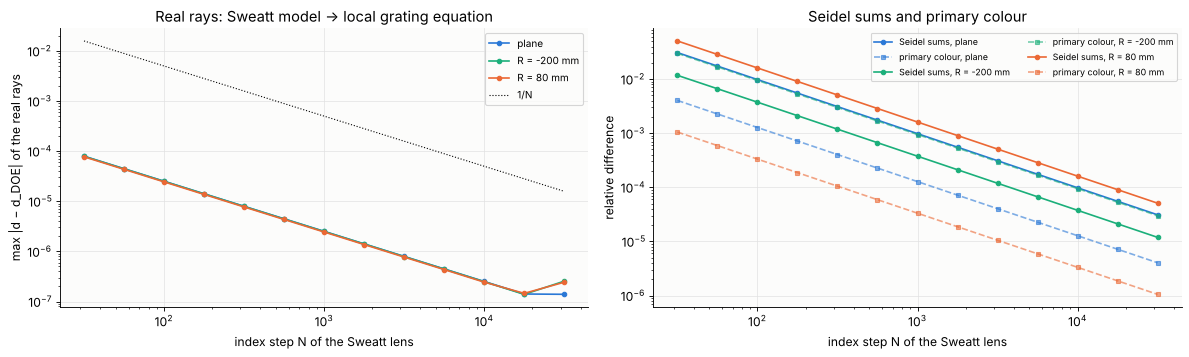

In [5]:
def test_lens(R2):
    S = [rt.Surface(60.0, 5.0, material=BK7, semi_diameter=10.0),
         rt.DiffractiveSurface(R2, 90.0, phase=(-300.0, 20.0), norm_radius=10.0, n_after=1.0,
                               semi_diameter=10.0)]
    return rt.System(S, 0, WL["d"], field_angle=np.radians(5))


Ns = np.logspace(1.5, 4.5, 13)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.6))
for R2, col in ((np.inf, BLUE), (-200.0, GREEN), (80.0, ORANGE)):
    s = test_lens(R2)
    sd = s.seidel().total
    cs = s.chromatic_seidel(WL["C"] - WL["F"]).total
    py = np.linspace(-1, 1, 11)
    b = s.trace_pupil(np.radians(5), 0.0, py)
    e_ray, e_seidel, e_colour = [], [], []
    for N in Ns:
        sw = s.sweatt_model(N)
        bs = sw.trace_pupil(np.radians(5), 0.0, py)
        e_ray.append(np.abs(bs.directions[-1] - b.directions[-1]).max())
        e_seidel.append(np.abs(sw.seidel().total - sd).max()/np.abs(sd).max())
        e_colour.append(np.abs(sw.chromatic_seidel(WL["C"] - WL["F"]).total - cs).max()/np.abs(cs).max())
    name = "plane" if np.isinf(R2) else f"R = {R2:g} mm"
    ax1.loglog(Ns, e_ray, "o-", color=col, ms=4, label=name)
    ax2.loglog(Ns, e_seidel, "o-", color=col, ms=4, label=f"Seidel sums, {name}")
    ax2.loglog(Ns, e_colour, "s--", color=col, ms=4, alpha=0.6, label=f"primary colour, {name}")
ax1.loglog(Ns, 0.5/Ns, "k:", lw=1, label="1/N")
ax1.set_xlabel("index step N of the Sweatt lens")
ax1.set_ylabel("max |d − d_DOE| of the real rays")
ax1.set_title("Real rays: Sweatt model → local grating equation")
ax1.legend(fontsize=9)
ax2.set_xlabel("index step N of the Sweatt lens")
ax2.set_ylabel("relative difference")
ax2.set_title("Seidel sums and primary colour")
ax2.legend(fontsize=8, ncol=2)
fig.tight_layout()

All three converge like $1/N$: the real rays of the Sweatt model to
those of the local grating equation, and its Seidel sums and primary
colour, computed with the ordinary formulas for refracting surfaces, to
the closed forms of `DiffractiveSurface`. With $N = 10^4$, a common choice
in lens design codes before diffractive surfaces became standard, the
model is good to about $10^{-4}$.

## 3. Dispersion: V = −3.45

With $\varphi_D \propto \lambda$, the "Abbe number" of a diffractive lens is

$$
V_D = \frac{\varphi_D(\lambda_d)}{\varphi_D(\lambda_F) - \varphi_D(\lambda_C)}
= \frac{\lambda_d}{\lambda_F - \lambda_C} = -3.45 ,
$$

negative and twenty times stronger than any glass, and its relative
partial dispersion is

$$
P_{g,F} = \frac{\lambda_g - \lambda_F}{\lambda_F - \lambda_C} = 0.296,
$$

far below the normal line of the glasses ($P_{g,F} \approx 0.64$ at
$V = 0$). On the partial dispersion diagram of notebook
[61 (glass catalogues)](61_glass_catalogues.ipynb) the kinoform is a point far
off to the left and low down.

V_D = -3.453, P_gF = 0.2956


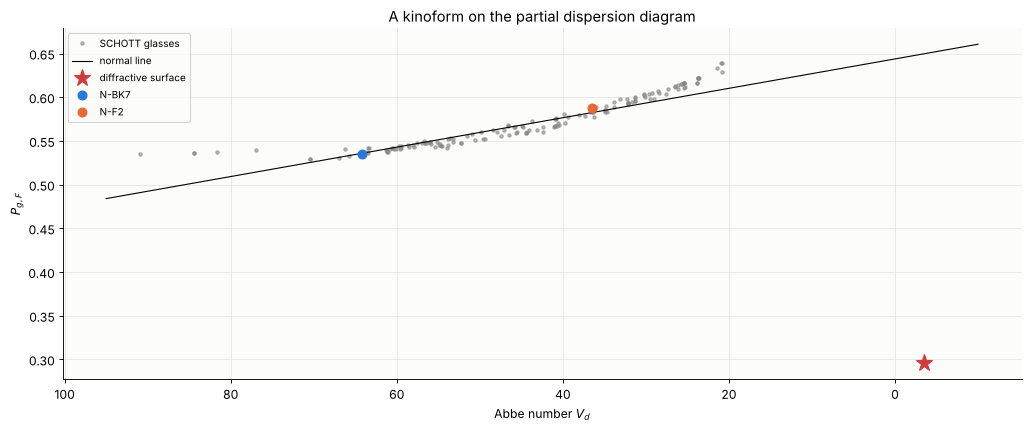

In [6]:
V_doe = fresnel.diffractive_abbe_number(*(gl.LINES[k] for k in "dFC"))
P_doe = (gl.LINES["g"] - gl.LINES["F"])/(gl.LINES["F"] - gl.LINES["C"])
print(f"V_D = {V_doe:.3f}, P_gF = {P_doe:.4f}")

t = gl.catalog("schott").table()
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.plot(t.Vd, t.PgF, "o", ms=3, color=GREY, alpha=0.6, label="SCHOTT glasses")
V = np.linspace(-10, 95, 2)
ax.plot(V, gl.normal_line(V), "k-", lw=1, label="normal line")
ax.plot(V_doe, P_doe, "*", ms=16, color=RED, label="diffractive surface")
for g, col in ((BK7, BLUE), (F2, ORANGE)):
    ax.plot(g.V_d, g.partial_dispersion(), "o", ms=8, color=col, label=g.name)
ax.invert_xaxis()
ax.set_xlabel("Abbe number $V_d$")
ax.set_ylabel("$P_{g,F}$")
ax.set_title("A kinoform on the partial dispersion diagram")
ax.legend(fontsize=9)
fig.tight_layout()

Two consequences for the thin lens formulas of notebook
[61 (glass catalogues)](61_glass_catalogues.ipynb). An achromat of a
glass with $V_1$ and a kinoform splits the power as
$\varphi_1 = \varphi V_1/(V_1 - V_D)$ and
$\varphi_D = -\varphi V_D/(V_1 - V_D)$: for N-BK7 the kinoform takes only
5 % of the power, where the flint of a glass doublet takes a negative
power of the order of the whole lens; the crown can be weak and nearly
free of aberrations. But the secondary spectrum
$\Delta s_g = -f\,(P_1 - P_D)/(V_1 - V_D)$ is not smaller: the
partial dispersion of the kinoform lies even further from that of N-BK7
than F2 does, on the other side, and the secondary spectrum is almost
twice that of N-BK7/N-F2, of the opposite sign. A hybrid achromat is
lighter and simpler, not better in the secondary spectrum. Together with a glass doublet, however, the
kinoform supplies the third, far off-line "glass" that an apochromat
needs (section 5).

## 4. A hybrid achromat

The hybrid achromat: an N-BK7 lens with the kinoform on its back, f =
100 mm at F/5, 1° field. Variables: the two curvatures and the phase
terms $A_1$, $A_2$ (`lo.diffractive()`, as phases at the rim). The focal
length and the F − C focus are constraints, spherical aberration and coma
from the Seidel sums the operands, the same set as for the glass doublets
of notebook [61 (glass catalogues)](61_glass_catalogues.ipynb), which is
built here again for comparison.

In [7]:
def focal_shift(a, b):
    def shift(s):
        return lo.focal_shift(WL[a], WL[b], tolerance=1.0)(s)[0]
    shift.__name__ = f"{a} - {b}"
    return shift


OPS = [lo.seidel("W040", 0.0, 0.01), lo.seidel("W131", 0.0, 0.01)]
ACHROMAT = [lo.Constraint(lo.paraxial_value("efl"), 100.0, 100.0, 1e-3, "efl"),
            lo.Constraint(focal_shift("F", "C"), 0.0, 0.0, 1e-4, "F - C")]


def optimize(system, variables, constraints):
    opt = lo.DampedLeastSquares(system, variables, OPS, constraints,
                                solves=[lo.solve_paraxial_focus()])
    return opt.run().system


def glass_doublet(crown, flint, f=100.0, epd=20.0, doe=False):
    (n1, V1), (n2, V2) = crown.model, flint.model
    p1, p2 = V1/(V1 - V2)/f, -V2/(V1 - V2)/f
    c1 = p1/(n1 - 1)/2
    c3 = -c1 - p2/(n2 - 1)
    back = (rt.DiffractiveSurface(1/c3, f, phase=(0.0,), norm_radius=10.0, n_after=1.0,
                                  semi_diameter=11.0) if doe
            else rt.Surface(1/c3, f, n_after=1.0, semi_diameter=11.0))
    S = [rt.Surface(1/c1, 6.0, material=crown, semi_diameter=11.0),
         rt.Surface(-1/c1, 3.0, material=flint, semi_diameter=11.0), back]
    return rt.System(S, 0, WL["d"], field_angle=np.radians(1.0), entrance_pupil_radius=epd/2)


designs = {}
s = glass_doublet(BK7, F2)
designs["N-BK7/N-F2 doublet"] = optimize(s, lo.curvatures(s), ACHROMAT)

n1, V1 = BK7.model
phi_1, phi_D = V1/(V1 - V_doe)/100.0, -V_doe/(V1 - V_doe)/100.0
print(f"thin hybrid achromat: N-BK7 {phi_1*100:.3f} phi, kinoform {phi_D*100:.3f} phi; "
      f"secondary spectrum {-100*(BK7.partial_dispersion() - P_doe)/(V1 - V_doe)*1e3:.0f} µm "
      f"(N-BK7/N-F2: {gl.secondary_spectrum(BK7, F2, 100.0)*1e3:.0f} µm)")
S = [rt.Surface(2*(n1 - 1)/phi_1, 5.0, material=BK7, semi_diameter=11.0),
     rt.DiffractiveSurface.from_power(phi_D, WL["d"], R=np.inf, thickness=100.0, n_after=1.0,
                                      norm_radius=10.0, semi_diameter=11.0)]
s = rt.System(S, 0, WL["d"], field_angle=np.radians(1.0), entrance_pupil_radius=10.0)
designs["N-BK7 + kinoform"] = optimize(s, [lo.Curvature(0), lo.Curvature(1)] + lo.diffractive(1, 10.0),
                                       ACHROMAT)
for name, s in designs.items():
    sd = s.seidel()
    print(f"{name:20s}: R = {[round(float(x.R), 1) for x in s.surfaces]}, "
          f"W040 {sd.W040:.4f}, W131 {sd.W131:.4f} waves, efl {s.paraxial().efl:.3f} mm")
h = designs["N-BK7 + kinoform"]
k = h.surfaces[1]
print(f"kinoform: A = {np.round(k.phase, 2)}, power share {k.diffractive_power(WL['d'])*100:.3f}, "
      f"{len(k.zone_radii(r_max=10.0))} zones, narrowest period {k.local_period(10.0)*1e3:.0f} µm, "
      f"depth {h.kinoform_depth(1)*1e3:.2f} µm")

thin hybrid achromat: N-BK7 0.949 phi, kinoform 0.051 phi; secondary spectrum -354 µm (N-BK7/N-F2: 192 µm)
N-BK7/N-F2 doublet  : R = [48.0, -39.3, -335.8], W040 0.5495, W131 -1.1289 waves, efl 100.000 mm
N-BK7 + kinoform    : R = [56.5, -1514.7], W040 0.0000, W131 -0.0000 waves, efl 100.000 mm


kinoform: A = [-286.86   29.45], power share 0.054, 40 zones, narrowest period 138 µm, depth 1.14 µm


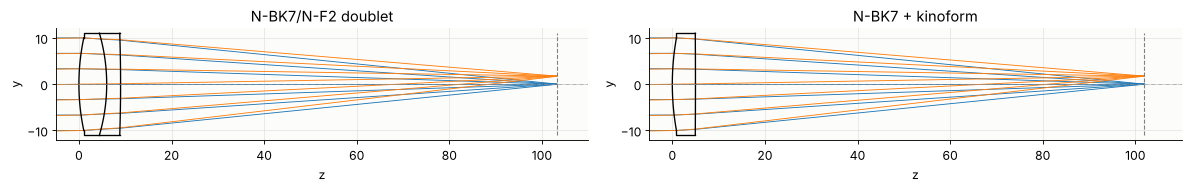

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
for ax, (name, s) in zip(axes, designs.items()):
    s.draw(ax=ax, fields=(0.0, s.max_field), n_rays=7)
    ax.set_title(name)
    ax.set_adjustable("box")   # keep the equal aspect, honour the x limits
    ax.set_xlim(-5, 110)
fig.tight_layout()

The hybrid is corrected for spherical aberration and coma at F/5; the
cemented glass doublet, as in notebook [61 (glass catalogues)](61_glass_catalogues.ipynb),
cannot correct both with these glasses and keeps about a wave of coma.
The hybrid is a nearly plano-convex N-BK7 lens, much weaker than the
crown of the doublet (it need not overcome a flint), with a kinoform of
about 40 zones whose narrowest zone is about 140 µm wide: an easy part to
mould or diamond turn. Its $A_2$ term does the work of an asphere.

The focus over the visible spectrum: both bring F and C together, the
glass doublet with the familiar parabola, the hybrid with a parabola of
the opposite curvature and a larger secondary spectrum, as the thin lens
formula says.

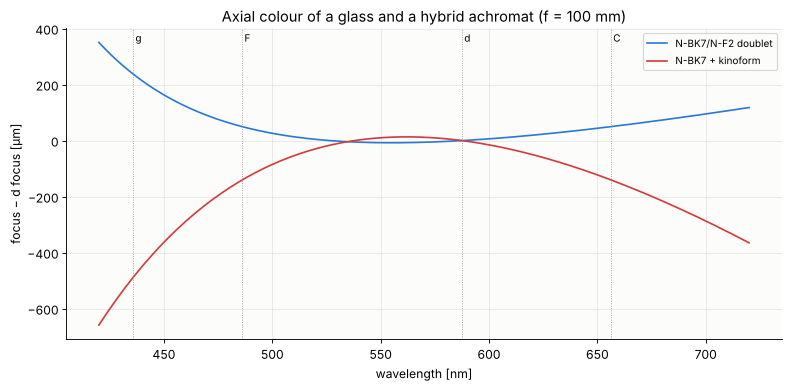

In [9]:
wl = np.linspace(420, 720, 151)


def focus_curve(s):
    z0 = s.paraxial().image_distance
    return np.array([s.with_wavelength(w*1e-6).paraxial().image_distance - z0 for w in wl])*1e3


fig, ax = plt.subplots(figsize=(10, 5))
for (name, s), col in zip(designs.items(), (BLUE, RED)):
    ax.plot(wl, focus_curve(s), color=col, label=name)
for line in "gFdC":
    ax.axvline(gl.LINES[line], color="0.6", lw=0.8, ls=":")
    ax.annotate(line, (gl.LINES[line], 1), xycoords=("data", "axes fraction"), fontsize=9,
                xytext=(2, -12), textcoords="offset points")
ax.set_xlabel("wavelength [nm]")
ax.set_ylabel("focus − d focus [µm]")
ax.set_title("Axial colour of a glass and a hybrid achromat (f = 100 mm)")
ax.legend(fontsize=9)
fig.tight_layout()

## 5. A hybrid apochromat

An apochromat brings three wavelengths to one focus, which needs three
materials not on one line of the partial dispersion diagram. Notebook
[61 (glass catalogues)](61_glass_catalogues.ipynb) searched the catalogue
for an anomalous pair and found N-FK58/N-LAF34, which cuts the secondary
spectrum by four but still leaves a residual. Here the kinoform is the
third material: the ordinary N-BK7/N-F2 doublet with a kinoform on its
last surface, with the g − F focus as a third constraint. The thin lens
powers follow from

$$
\sum \varphi_i = \varphi,\qquad \sum \frac{\varphi_i}{V_i} = 0,\qquad
\sum \frac{P_i\,\varphi_i}{V_i} = 0 .
$$

thin apochromat, powers in units of phi: [ 1.834 -0.852  0.018]
traced: kinoform share 0.019, R = [58.0, -52.6, -210.4], W040 0.0000, W131 0.0000
13 zones, narrowest 458 µm


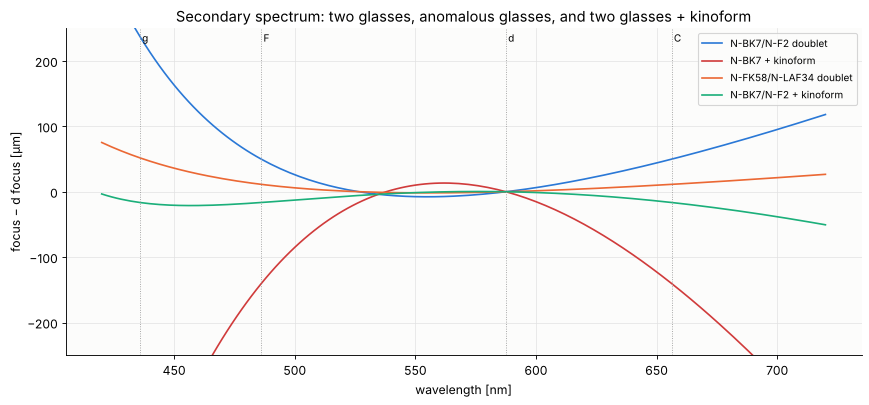

In [10]:
APO = ACHROMAT + [lo.Constraint(focal_shift("g", "F"), 0.0, 0.0, 1e-4, "g - F")]
s = glass_doublet(gl.get("N-FK58"), gl.get("N-LAF34"))
designs["N-FK58/N-LAF34 doublet"] = optimize(s, lo.curvatures(s), ACHROMAT)
s = glass_doublet(BK7, F2, doe=True)
designs["N-BK7/N-F2 + kinoform"] = optimize(s, lo.curvatures(s) + lo.diffractive(2, 10.0), APO)

# thin lens powers of the three "materials"
M = np.array([[1, 1, 1], [1/BK7.V_d, 1/F2.V_d, 1/V_doe],
              [BK7.partial_dispersion()/BK7.V_d, F2.partial_dispersion()/F2.V_d, P_doe/V_doe]])
print("thin apochromat, powers in units of phi:", np.round(np.linalg.solve(M, [1, 0, 0]), 3))
apo = designs["N-BK7/N-F2 + kinoform"]
k = apo.surfaces[2]
sd = apo.seidel()
print(f"traced: kinoform share {k.diffractive_power(WL['d'])*100:.3f}, R = "
      f"{[round(float(x.R), 1) for x in apo.surfaces]}, W040 {sd.W040:.4f}, W131 {sd.W131:.4f}")
print(f"{len(k.zone_radii(r_max=10.0))} zones, narrowest {k.local_period(10.0)*1e3:.0f} µm")

fig, ax = plt.subplots(figsize=(11, 5.2))
for (name, s), col in zip(designs.items(), (BLUE, RED, ORANGE, GREEN)):
    ax.plot(wl, focus_curve(s), color=col, label=name)
for line in "gFdC":
    ax.axvline(gl.LINES[line], color="0.6", lw=0.8, ls=":")
    ax.annotate(line, (gl.LINES[line], 1), xycoords=("data", "axes fraction"), fontsize=9,
                xytext=(2, -12), textcoords="offset points")
ax.set_ylim(-250, 250)
ax.set_xlabel("wavelength [nm]")
ax.set_ylabel("focus − d focus [µm]")
ax.set_title("Secondary spectrum: two glasses, anomalous glasses, and two glasses + kinoform")
ax.legend(fontsize=9)
fig.tight_layout()

The ordinary achromat with a kinoform worth about 2 % of its power
brings g, F and C to one focus. Its curve stays within ±20 µm from 450
to 650 nm, flatter than that of the anomalous glass pair, which needed
two special glasses and still has its residual in the blue; it uses the
two cheapest glasses in the catalogue, and the kinoform has only 13
zones. Both glasses also become weaker than in the plain achromat (1.83
and −0.85 instead of 2.31 and −1.31 times the total power), since the
kinoform takes over part of the colour correction, and the lens is
corrected for spherical aberration and coma as well.

## 6. Efficiency: where the other orders go

Only the design order goes to the focus. A kinoform whose zones are
$p$ waves deep at the design wavelength $\lambda_0$ (here $p = 1$, depth
$\lambda_0/(n - 1)$) delays by
$\alpha = p\,\lambda_0 (n(\lambda) - 1)/(\lambda\,(n_0 - 1))$ waves at
$\lambda$, and the scalar efficiency of the order $m$ is
$\eta_m = \mathrm{sinc}^2(\alpha - m)$ (`fresnel.kinoform_efficiency()`,
notebook [51 (Fresnel lenses)](51_fresnel_lenses.ipynb)). The rest goes into
the order 0, with the power of the glass alone, and the order 2, with
twice the diffractive power: out of focus light that lowers the contrast
of the image, worst at the ends of the band. A harmonic (multi-order)
lens with $p = 10$ waves and $m = 10$ has efficiency peaks at
$\lambda_0 p/m'$ for every order $m'$, at the price of a much deeper
relief.

kinoform depth 1.061 µm; band average 450-650 nm: 0.957, minimum 0.68 at 420 nm
harmonic lens: depth 10.61 µm, same efl: 100.000 mm, peaks at [688. 611. 550. 500. 458.] nm


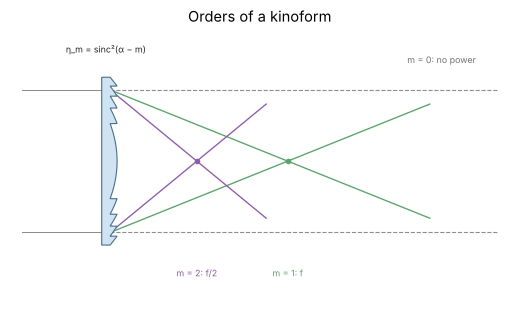

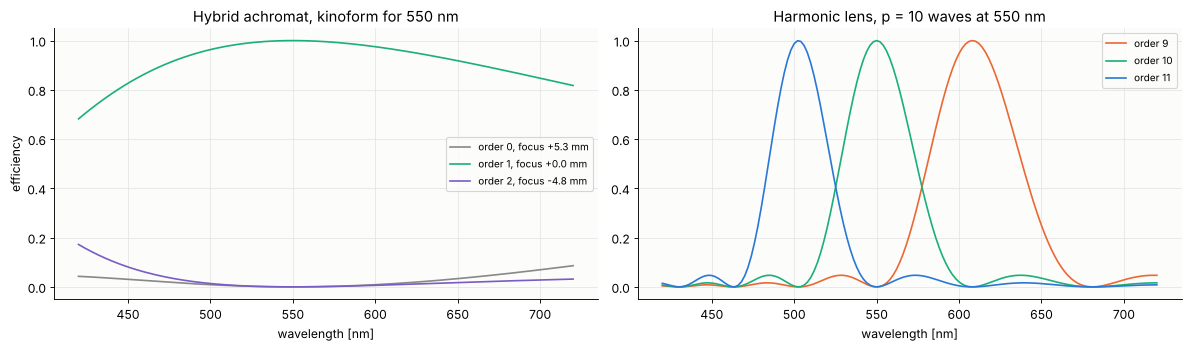

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.0))
sketch.hybrid_lens_layout(ax, "orders", title="Orders of a kinoform")
fig.tight_layout()

h = designs["N-BK7 + kinoform"].copy()
h.surfaces[1].design_wavelength = 550e-6
wls = wl*1e-6
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))
for m, col in ((0, GREY), (1, GREEN), (2, PURPLE)):
    other = h.copy()
    other.surfaces[1].order = m
    eta = other.diffraction_efficiency(wls)
    z = other.paraxial().image_distance - h.paraxial().image_distance
    ax1.plot(wl, eta, color=col, label=f"order {m}, focus {z:+.1f} mm")
eta1 = h.diffraction_efficiency(wls)
print(f"kinoform depth {h.kinoform_depth(1)*1e3:.3f} µm; band average 450-650 nm: "
      f"{np.mean(eta1[(wl >= 450) & (wl <= 650)]):.3f}, minimum {eta1.min():.2f} at {wl[np.argmin(eta1)]:.0f} nm")
ax1.set_xlabel("wavelength [nm]")
ax1.set_ylabel("efficiency")
ax1.set_title("Hybrid achromat, kinoform for 550 nm")
ax1.legend(fontsize=9)
harm = h.copy()
k = harm.surfaces[1]
k.phase, k.order, k.design_order = tuple(np.array(k.phase)/10), 10, 10
print(f"harmonic lens: depth {harm.kinoform_depth(1)*1e3:.2f} µm, same efl: "
      f"{harm.paraxial().efl:.3f} mm, peaks at", np.round(550*10/np.arange(8, 13), 0), "nm")
for m, col in ((9, ORANGE), (10, GREEN), (11, BLUE)):
    k.order = m
    ax2.plot(wl, harm.diffraction_efficiency(wls), color=col, label=f"order {m}")
ax2.set_xlabel("wavelength [nm]")
ax2.set_title("Harmonic lens, p = 10 waves at 550 nm")
ax2.legend(fontsize=9)
fig.tight_layout()

A one-wave kinoform keeps 96 % in the first order on average from 450 to
650 nm and drops to about 70 % at 420 nm. The orders 0 and 2
come to a focus millimetres away and spread over a wide disk in the image
plane, a halo of a few percent of the light: harmless for a laser or a
narrow band, visible as a loss of contrast around bright objects in
broadband imaging. It was the reason why the first hybrid camera lenses
(Canon's DO lenses) used two stacked kinoforms of different materials,
whose efficiency stays high over the whole band. The harmonic lens behaves
like a refractive lens in narrow bands around its peaks; between them,
the light goes into neighbouring orders with other focal lengths.

## 7. A hybrid singlet for thermal imaging

In the long wave infrared (8 to 12 µm) the wavelength is twenty times
longer: the zones are twenty times wider and fewer, the relief is still
only about 7 µm deep in ZnSe, and diamond turning cuts the kinoform and
an asphere on the same lens in one setup. The diffractive Abbe number in
this band is $10/(8 - 12) = -2.5$.

Three singlets of f = 50 mm at F/1.5 with ±4° field (a 640 × 512 detector
of 17 µm pixels sees about ±6°), all with two aspheric surfaces,
optimized on polychromatic ray errors at 8, 10 and 12 µm:

- germanium, $n = 4.0$ and $V \approx 800$: hardly any colour, the
  usual choice, but expensive and its index drops with temperature,
- ZnSe, $n = 2.4$ and $V \approx 58$: cheaper, but the colour dominates,
- ZnSe with a kinoform on its back.

In [12]:
WL_IR = 10e-3
WLS_IR = (8e-3, 10e-3, 12e-3)
V_ir = {name: (n(10000) - 1)/(n(8000) - n(12000))
        for name, n in (("Ge", germanium_index), ("ZnSe", zinc_selenide_index))}
print("V(8-12 µm):", {k: round(v, 1) for k, v in V_ir.items()}, "kinoform", 10/(8 - 12))


def ir_singlet(material, doe=False, f=50.0, epd=33.0):
    c1 = 1/((material(10000) - 1)*f)
    back = (rt.DiffractiveSurface(np.inf, f, phase=(0.0,), norm_radius=20.0, n_after=1.0,
                                  semi_diameter=18.0) if doe
            else rt.Surface(np.inf, f, n_after=1.0, semi_diameter=18.0))
    S = [rt.Surface(np.inf, 0.0, semi_diameter=epd/2, label="stop"),
         rt.Surface(1/c1, 5.0, material=material, semi_diameter=18.0), back]
    return rt.System(S, 0, WL_IR, field_angle=np.radians(4)).at_paraxial_focus()


ir = {}
for name, material, doe in (("Ge asphere", germanium_index, False),
                            ("ZnSe asphere", zinc_selenide_index, False),
                            ("ZnSe asphere + kinoform", zinc_selenide_index, True)):
    s = ir_singlet(material, doe)
    var = [lo.Curvature(1), lo.Curvature(2), lo.Thickness(2), lo.Aspheric(1, 4, 20.0),
           lo.Aspheric(1, 6, 20.0), lo.Aspheric(2, 4, 20.0), lo.Aspheric(2, 6, 20.0)]
    if doe:
        var += lo.diffractive(2, 20.0)
    opt = lo.DampedLeastSquares(s, var, [lo.polychromatic_ray_errors(WLS_IR, (0.0, 0.7, 1.0),
                                                                     tolerance=1e-3)],
                                [lo.Constraint(lo.paraxial_value("efl"), 50.0, 50.0, 1e-3, "efl")])
    ir[name] = opt.run(max_iterations=60).system

spot = lo.spot_rms((0.0, 0.7, 1.0), WLS_IR, tolerance=1e-3)
mono = lo.spot_rms((0.0, 0.7, 1.0), (WL_IR,), tolerance=1e-3)
airy = 1.22*WL_IR*1.5
print(f"Airy radius at 10 µm, F/1.5: {airy*1e3:.0f} µm")
for name, s in ir.items():
    print(f"{name:24s}: RMS spot 8-12 µm {np.round(spot(s), 1)} µm, 10 µm alone {np.round(mono(s), 1)} µm "
          f"(fields 0, 0.7, 1)")
k = ir["ZnSe asphere + kinoform"].surfaces[2]
hyb = ir["ZnSe asphere + kinoform"]
eta = hyb.diffraction_efficiency(np.linspace(8e-3, 12e-3, 81))
print(f"kinoform: {k.diffractive_power(WL_IR)*50:.3f} of the power, "
      f"{len(k.zone_radii(r_max=16.5))} zones, narrowest {k.local_period(16.5)*1e3:.0f} µm, "
      f"depth {hyb.kinoform_depth(2)*1e3:.1f} µm, efficiency {eta.min():.2f} to 1, mean {eta.mean():.3f}")

V(8-12 µm): {'Ge': np.float64(784.5), 'ZnSe': np.float64(57.8)} kinoform -2.5


Airy radius at 10 µm, F/1.5: 18 µm
Ge asphere              : RMS spot 8-12 µm [35.7 17.6 49.4] µm, 10 µm alone [36.2 16.2 48.1] µm (fields 0, 0.7, 1)


ZnSe asphere            : RMS spot 8-12 µm [93.9 87.8 99.9] µm, 10 µm alone [29.  15.1 55. ] µm (fields 0, 0.7, 1)
ZnSe asphere + kinoform : RMS spot 8-12 µm [35.8 13.1 49. ] µm, 10 µm alone [28.5 15.1 55. ] µm (fields 0, 0.7, 1)
kinoform: 0.047 of the power, 12 zones, narrowest 675 µm, depth 7.1 µm, efficiency 0.80 to 1, mean 0.950


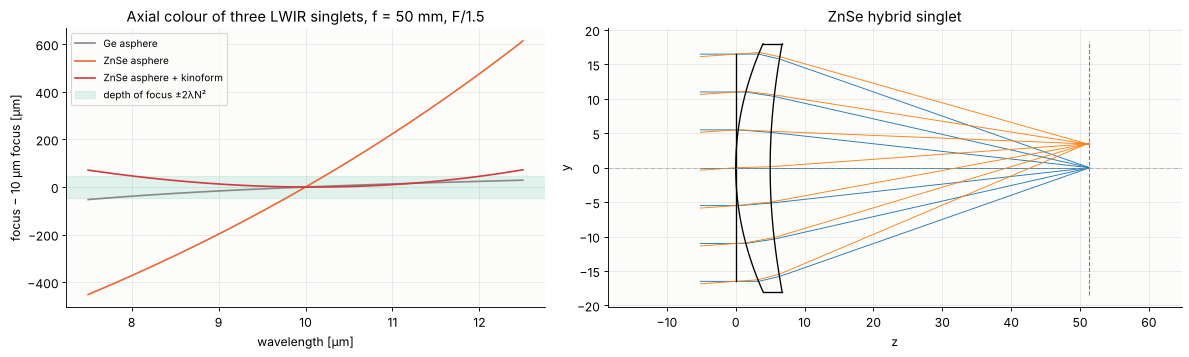

In [13]:
wl_ir = np.linspace(7.5, 12.5, 101)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1, 1.2]})
for (name, s), col in zip(ir.items(), (GREY, ORANGE, RED)):
    z0 = s.paraxial().image_distance
    ax1.plot(wl_ir, [(s.with_wavelength(w*1e-3).paraxial().image_distance - z0)*1e3 for w in wl_ir],
             color=col, label=name)
ax1.axhspan(-2*1.5**2*WL_IR*1e3, 2*1.5**2*WL_IR*1e3, color=GREEN, alpha=0.12,
            label="depth of focus ±2λN²")
ax1.set_xlabel("wavelength [µm]")
ax1.set_ylabel("focus − 10 µm focus [µm]")
ax1.set_title("Axial colour of three LWIR singlets, f = 50 mm, F/1.5")
ax1.legend(fontsize=9)
hyb.draw(ax=ax2, fields=(0.0, hyb.max_field), n_rays=7)
ax2.set_title("ZnSe hybrid singlet")
fig.tight_layout()

The ZnSe asphere is limited by its colour: its spot at 10 µm alone is
as small as that of the germanium lens, but over the band it grows by a
factor of three, with an axial colour of about a millimetre over the
band against a depth of focus of ±45 µm. A kinoform with 5 % of the
power and only 12 zones, the narrowest about 0.7 mm wide, removes it: the hybrid ZnSe singlet reaches the polychromatic spot
of the germanium lens, while keeping more than 80 % efficiency at the
band edges. The same trick serves chalcogenide glasses, which can be
moulded together with their kinoform, in low cost thermal cameras;
it also helps against thermal defocus, since the diffractive power does
not depend on the index and changes only through the expansion of the
zone radii, not part of this notebook.

In [14]:
print(f"run time {time.time() - t_start:.0f} s")

run time 149 s


## Summary

- `raytrace.DiffractiveSurface` traces a rotationally symmetric phase
  polynomial on any base surface with the local grating equation; a ray
  behind it agrees with a `GratingSurface` of the local period.
- Its power $-m\lambda A_1/\pi r_n^2$ is proportional to the wavelength:
  Abbe number −3.45 (visible) or −2.5 (8 to 12 µm), $P_{g,F} = 0.296$.
- The Seidel sums and primary colour are those of the Sweatt model in the
  limit of infinite index, confirmed by `System.sweatt_model()` to $1/N$.
- An N-BK7 lens with a kinoform of 5 % of its power is an achromat, with a
  secondary spectrum like that of a glass doublet but of opposite sign.
- An N-BK7/N-F2 doublet with a kinoform of 2 % of its power is an
  apochromat, flatter than the anomalous glass doublet of notebook
  61 (glass catalogues).
- The price is the efficiency, $\mathrm{sinc}^2(\alpha - m)$, a halo of
  the orders 0 and 2 at the ends of the band.
- In the thermal infrared a kinoform of about a dozen zones on a ZnSe
  asphere matches a germanium singlet.

**Try it.**

- Put the kinoform of the hybrid achromat on the front surface, or on a
  curved back surface, and compare the Seidel sums.
- Optimize the apochromat with N-FK58/N-LAF34 instead of N-BK7/N-F2: how
  much power does the kinoform need then?
- Use a harmonic kinoform ($p = 2$) for the thermal singlet and compare
  the efficiency over the band.
- Trace the order 0 and 2 light of the hybrid achromat to the image plane
  with `surfaces[1].order` and add its PSF to that of the first order.

## References

- W. C. Sweatt, "Describing holographic optical elements as lenses", J. Opt. Soc. Am. 67, 803-808 (1977); "Mathematical equivalence between a holographic optical element and an ultra-high index lens", J. Opt. Soc. Am. 69, 486-487 (1979).
- T. Stone and N. George, "Hybrid diffractive-refractive lenses and achromats", Appl. Opt. 27, 2960-2971 (1988).
- D. A. Buralli, G. M. Morris and J. R. Rogers, "Optical performance of holographic kinoforms", Appl. Opt. 28, 976-983 (1989).
- D. C. O'Shea, T. J. Suleski, A. D. Kathman and D. W. Prather, *Diffractive Optics: Design, Fabrication, and Test*, SPIE Press (2004).
- D. W. Sweeney and G. E. Sommargren, "Harmonic diffractive lenses", Appl. Opt. 34, 2469-2475 (1995).
- W. T. Welford, *Aberrations of Optical Systems*, Adam Hilger (1986), ch. 13.
- R. Kingslake and R. B. Johnson, *Lens Design Fundamentals*, 2nd ed., Academic Press (2010).
- B. Tatian, "Fitting refractive-index data with the Sellmeier dispersion formula", Appl. Opt. 23, 4477-4485 (1984) (ZnSe).
- H. W. Icenogle, B. C. Platt and W. L. Wolfe, "Refractive indexes and temperature coefficients of germanium and silicon", Appl. Opt. 15, 2348-2351 (1976).